In [3]:
!pip install ttime tensorflow

In [28]:
# Manipulation de données et calcul numérique
import ttime
import time
import warnings
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# Préparation des données et extraction de caractéristiques textuelles (NLP)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline

# Modèles de Machine Learning
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Métriques d'évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Librairies Tensorflow por le Deep Learning
import itertools
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixation des graines aléatoires pour la reproductibilité
tf.random.set_seed(42)
np.random.seed(42)

# Configuration visuelle des graphiques et filtrage des avertissements mineurs
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
warnings.filterwarnings("ignore")

print("Bibliothèques chargées avec succès !")

Bibliothèques chargées avec succès !


# Détection d'e-mails de phishing : EDA et Benchmark Machine Learning
**Objectifs** :
- Explorer un jeu de données d'environ 80 000 e-mails (0 = légitime, 1 = phishing),
- Nettoyer correctement les données d'entraînement sans fuite de données (data leakage),
- Comparer plusieurs modèles de Machine Learning via des pipelines et des grilles de paramètres.

## 1. Chargement des données et premières vérifications

In [5]:
splits = {'train': 'data/train-00000-of-00001-4b508a55ac8e7a25.parquet', 'test': 'data/test-00000-of-00001-8a6d39996ec0fb5b.parquet'}
df_train = pd.read_parquet("hf://datasets/zionia/phishing-emails/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/zionia/phishing-emails/" + splits["test"])

df = pd.concat([df_train, df_test], ignore_index=True)

In [6]:
# 1. Dimension du DataFrame
print(f"Dimensions du dataset : {df.shape[0]} lignes et {df.shape[1]} colonnes")

# 2. Aperçu des premières lignes et informations sur les types
display(df.head())
print("\n--- Informations générales ---")
print(df.info())

# 3. Vérification des valeurs manquantes et des doublons
print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())
print(f"\nNombre de lignes strictement dupliquées : {df.duplicated().sum()}")

Dimensions du dataset : 82486 lignes et 2 colonnes


,text_combined,label
0,basil chupin oztzqpzotpgcomau aaron kulkis wro...,0
1,advice mon 27 dec 2004 11 16 55 0600 good day ...,1
2,daily top 10 nedhalla1965cadecocc daily top 10...,1
3,gale barton dwuvtmuvtcz safe highly effective ...,1
4,alon camille pttayloranitesystemscom dear f1b9...,1



--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82486 entries, 0 to 82485
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  82486 non-null  object
 1   label          82486 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.3+ MB
None

--- Valeurs manquantes par colonne ---
text_combined    0
label            0
dtype: int64

Nombre de lignes strictement dupliquées : 408


**Observations initiales :**

Cette étape permet de vérifier que les colonnes text et label sont bien présentes, d'identifier les valeurs nulles (NaN) et de repérer les doublons éventuels.

- Nombre de lignes dupliquées : 400
- Aucune valeur manquante

## 2. Analyse Exploratoire des Données (EDA)
### 2.1 Répartition des classes (0 vs 1)

Il est essentiel de vérifier si le jeu de données est équilibré ou non : un fort déséquilibre orienterait le choix de nos métriques d'évaluation (le F1-Score devenant alors bien plus fiable que l'accuracy seule).

,Nombre d'e-mails,Pourcentage (%)
label,,
1,42891,52.0
0,39595,48.0


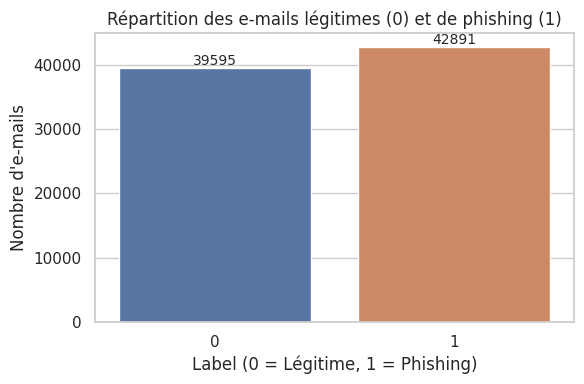

In [7]:
# Comptage brut et en pourcentage
repartition = df["label"].value_counts()
pourcentages = df["label"].value_counts(normalize=True) * 100

resume_labels = pd.DataFrame({
    "Nombre d'e-mails": repartition,
    "Pourcentage (%)": pourcentages.round(2)
})
display(resume_labels)

# Visualisation
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="label", hue="label", palette=["#4C72B0", "#DD8452"], legend=False)
ax.set_title("Répartition des e-mails légitimes (0) et de phishing (1)")
ax.set_xlabel("Label (0 = Légitime, 1 = Phishing)")
ax.set_ylabel("Nombre d'e-mails")

# Affichage des valeurs au-dessus des barres
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10
    )

plt.tight_layout()
plt.show()

**Observation :**

Ce graphique permet de voir que les deux classes sont équilibrées (proche de 50/50).

### 2.2 Longueur des e-mails (en mots et en caractères)

 Les e-mails de phishing ont souvent une structure particulière (messages très courts incitant à cliquer rapidement sur un lien, ou au contraire longs blocs copiés-collés => [Anatomie d'un email de phishing](https://rythm.xyz/blog/anatomy-of-modern-phishing-email/)).

 Calculer ces deux longueurs permet aussi de repérer les e-mails vides ou beaucoup trop grands.

--- Statistiques de longueur en MOTS par classe ---


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,39595.0,203.182,479.177,2.0,57.0,106.0,203.0,23359.0
1,42891.0,121.343,594.451,0.0,32.0,55.0,154.0,107710.0



--- Statistiques de longueur en CARACTÈRES par classe ---


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,39595.0,1536.096,3695.898,11.0,411.0,779.0,1493.0,160318.0
1,42891.0,1060.414,21192.696,1.0,241.0,391.0,1058.0,4279526.0


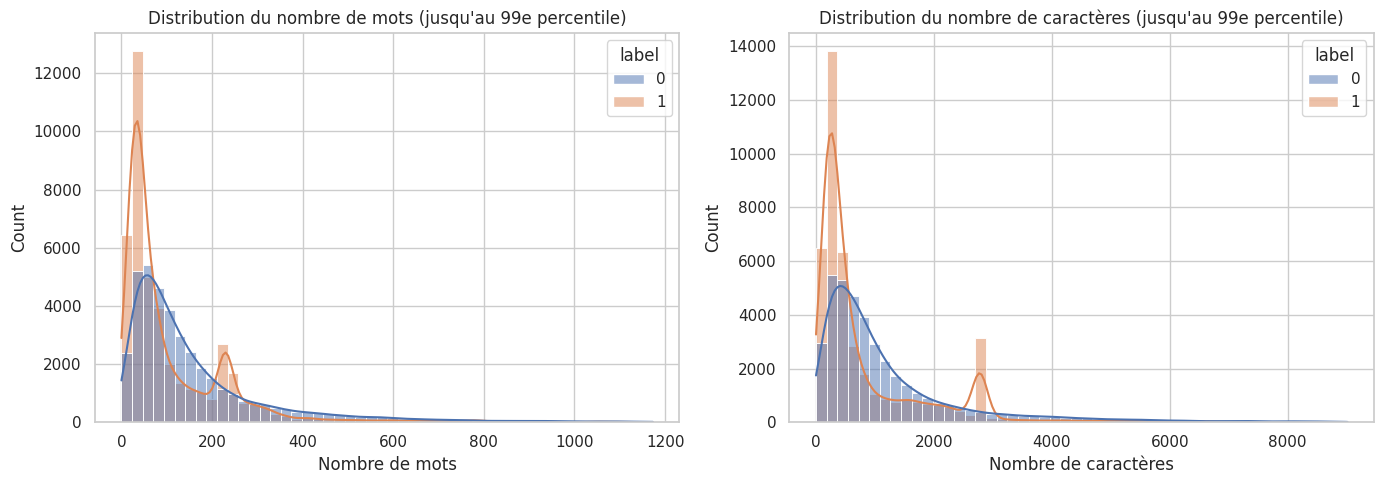

In [8]:
# On convertit temporairement les valeurs nulles en chaîne vide pour ne pas faire planter le calcul
textes_propres = df["text_combined"].fillna("").astype(str)

df["nb_caracteres"] = textes_propres.str.len()
df["nb_mots"] = textes_propres.str.split().str.len()

print("--- Statistiques de longueur en MOTS par classe ---")
display(df.groupby("label")["nb_mots"].describe().round(3))

print("\n--- Statistiques de longueur en CARACTÈRES par classe ---")
display(df.groupby("label")["nb_caracteres"].describe().round(3))

# Visualisation des distributions (limite d'affichage au 99e percentile pour que le graphique reste lisible)
seuil_mots = df["nb_mots"].quantile(0.99)
seuil_cars = df["nb_caracteres"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df[df["nb_mots"] <= seuil_mots],
    x="nb_mots", hue="label", bins=50, kde=True, ax=axes[0]
)
axes[0].set_title("Distribution du nombre de mots (jusqu'au 99e percentile)")
axes[0].set_xlabel("Nombre de mots")

sns.histplot(
    data=df[df["nb_caracteres"] <= seuil_cars],
    x="nb_caracteres", hue="label", bins=50, kde=True, ax=axes[1]
)
axes[1].set_title("Distribution du nombre de caractères (jusqu'au 99e percentile)")
axes[1].set_xlabel("Nombre de caractères")

plt.tight_layout()
plt.show()

**Observation :**

On compare généralement la médiane (50%) plutôt que la moyenne (mean), car les e-mails très longs (outliers des boites à moustache) tirent trop la moyenne vers le haut.

### 2.3 Recherche des valeurs aberrantes (Outliers)

Dans un jeu de données textuelles, deux types d'anomalies posent problème :

- Les e-mails vides ou quasi vides (0 mot), qui n'apportent aucun signal textuel.
- Les e-mails beaucoup trop longs (ex : erreurs d'encodage).

On utilise les boîtes à moustaches et la méthode de l'écart interquartile pour les quantifier.

$$IQR = Q3 - Q1$$

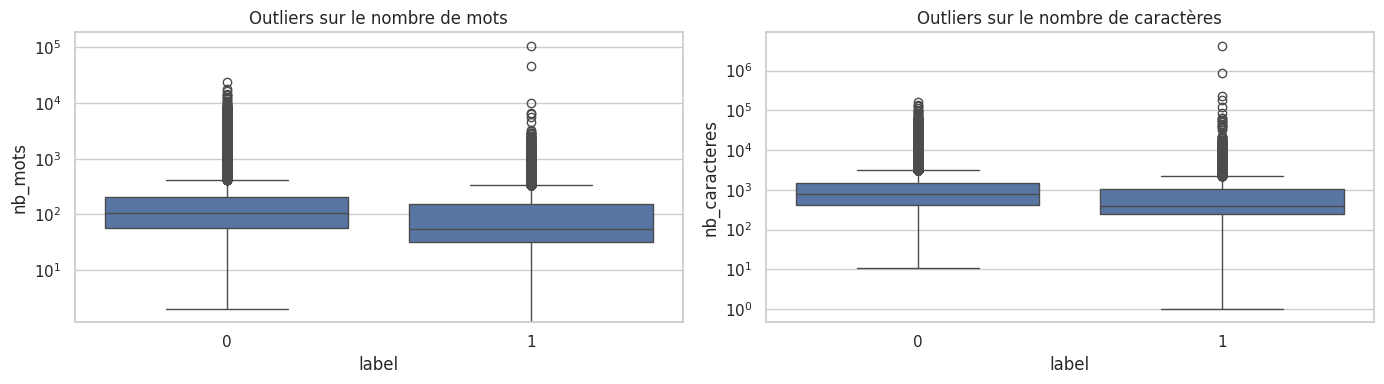

Q1 = 39 mots | Q3 = 183 mots | IQR = 144 mots
E-mails vides (0 mot) : 1
Outliers classiques (> 399 mots) : 5531 (6.71%)
Outliers extrêmes (> 615 mots) : 2687 (3.26%)

Aperçu des 5 e-mails les plus longs :


,label,nb_mots,nb_caracteres
4240,1,107710,4279526
63049,1,46425,868304
13265,0,23359,160318
28357,0,18118,126865
78107,0,16759,115618


In [14]:
# Boxplots => outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x="label", y="nb_mots", ax=axes[0])
axes[0].set_title("Outliers sur le nombre de mots")
axes[0].set_yscale("log")

sns.boxplot(data=df, x="label", y="nb_caracteres", ax=axes[1])
axes[1].set_title("Outliers sur le nombre de caractères")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

# Espace interquartile
Q1 = df["nb_mots"].quantile(0.25)
Q3 = df["nb_mots"].quantile(0.75)
IQR = Q3 - Q1

borne_sup_classique = Q3 + 1.5 * IQR
borne_sup_extreme = Q3 + 3.0 * IQR

nb_vides = (df["nb_mots"] == 0).sum()
nb_outliers_classiques = (df["nb_mots"] > borne_sup_classique).sum()
nb_outliers_extremes = (df["nb_mots"] > borne_sup_extreme).sum()

print(f"Q1 = {Q1:.0f} mots | Q3 = {Q3:.0f} mots | IQR = {IQR:.0f} mots")
print(f"E-mails vides (0 mot) : {nb_vides}")
print(f"Outliers classiques (> {borne_sup_classique:.0f} mots) : {nb_outliers_classiques} ({nb_outliers_classiques/len(df)*100:.2f}%)")
print(f"Outliers extrêmes (> {borne_sup_extreme:.0f} mots) : {nb_outliers_extremes} ({nb_outliers_extremes/len(df)*100:.2f}%)")

print("\nAperçu des 5 e-mails les plus longs :")
display(df.nlargest(5, "nb_mots")[["label", "nb_mots", "nb_caracteres"]])

**Observations :**

- **Nombre de mots :** Les e-mails légitimes (0) ont une médiane située autour de 100 mots ($10^2$), avec la moitié centrale comprise à peu près entre 80 et 330 mots. Les e-mails de phishing (1) sont nettement plus courts, avec une médiane autour de 60 à 65 mots et une boîte située entre 50 et 150 mots.   
- **Nombre de caractères :** Même tendance, avec une médiane proche de 900-950 caractères pour les légitimes contre environ 550-600 caractères pour le phishing.

Pour les e-mails d phishing, la moustache descend jusqu'à 1 seul caractère ($10^0$) et 1 seul mot (voire 0) = revérifier le nettoyage avant l'entraînement.

###2.4 Top 20 des mots les plus fréquents (Label 0 vs Label 1)

On utilise CountVectorizer en retirant les stopwords pour faire ressortir uniquement le vocabulaire porteur de sens.

<Axes: title={'center': 'n mots les plus fréquents pour le Label 0'}, xlabel='Fréquence', ylabel='Mot'>

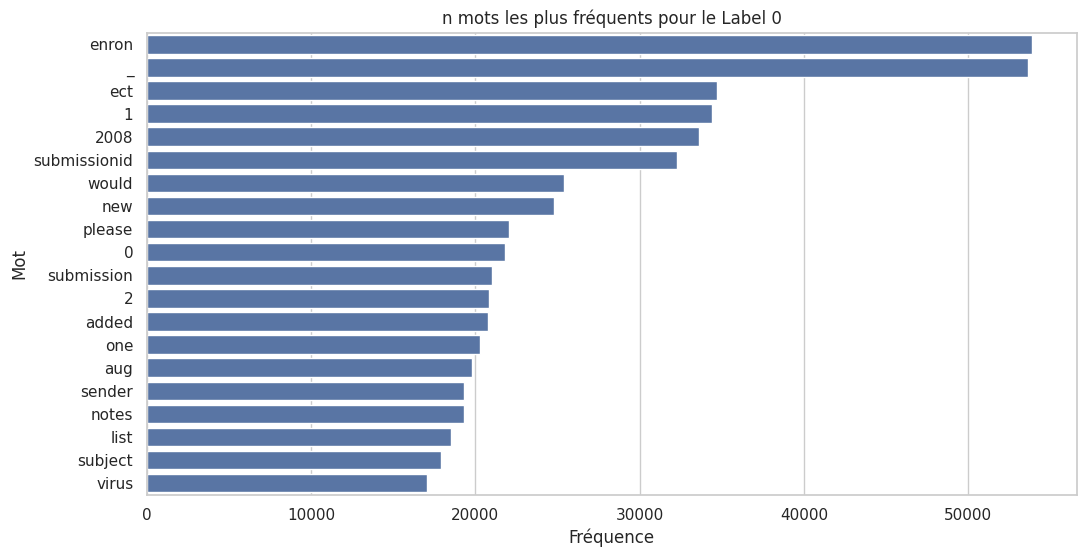

In [24]:
all_words_legit = " ".join(df[df["label"] == 0]["text_combined"]).lower().split()

word_counts = Counter(all_words_legit)

most_common_words = word_counts.most_common(20)

words_df = pd.DataFrame(
    most_common_words,
    columns=["Mot", "Fréquence"]
)

plt.figure(figsize=(12, 6))
plt.title("n mots les plus fréquents pour le Label 0")

sns.barplot(
    data=words_df,
    x="Fréquence",
    y="Mot"
)

<Axes: title={'center': 'n mots les plus fréquents pour le Label 1'}, xlabel='Fréquence', ylabel='Mot'>

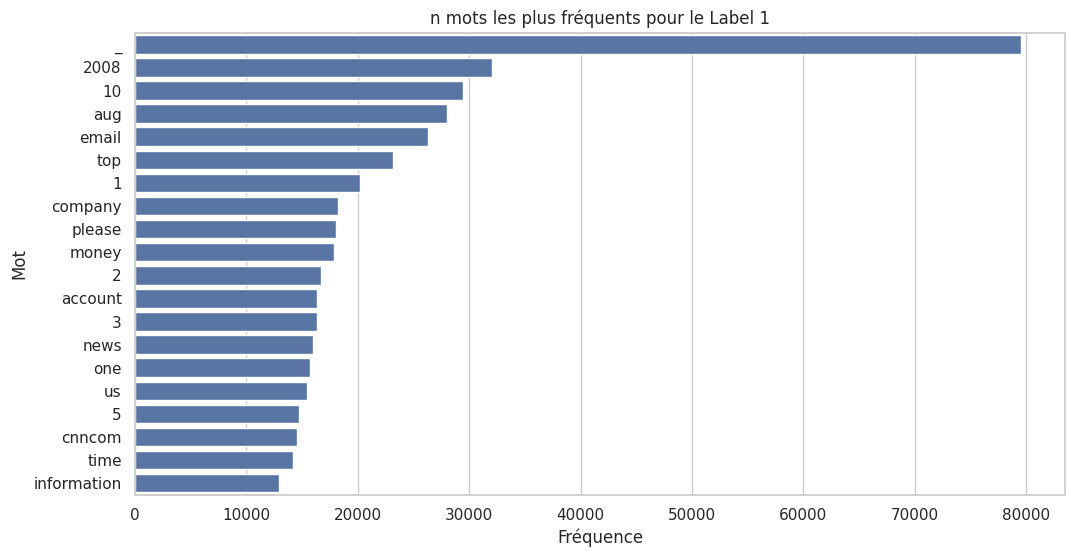

In [25]:
all_words_phishing = " ".join(df[df["label"] == 1]["text_combined"]).lower().split()

word_counts = Counter(all_words_phishing)

most_common_words = word_counts.most_common(20)

words_df = pd.DataFrame(
    most_common_words,
    columns=["Mot", "Fréquence"]
)

plt.figure(figsize=(12, 6))
plt.title("n mots les plus fréquents pour le Label 1")

sns.barplot(
    data=words_df,
    x="Fréquence",
    y="Mot"
)

**Observation :**

Cette comparaison met généralement en évidence un vocabulaire plus transactionnel, urgent ou technique dans la classe 1 (ex : please, money, time, etc.) par rapport aux échanges classiques de la classe 0. Cela confirme que la fréquence des mots (TF-IDF) sera une très bonne représentation pour nos modèles.

## 3. Séparation Train / Test et Nettoyage du jeu d'entraînement

On effectue le découpage train / test (80% / 20%) avant tout nettoyage d'outliers ou vectorisation.

On utilise `stratify=y` pour conserver exactement la même proportion de phishing dans le train et le test.

On nettoie uniquement le jeu de train (valeurs nulles, textes vides, doublons et outliers extrêmes calculés uniquement sur le train).

Le jeu de test reste intact afin d'évaluer nos modèles en conditions réelles.

In [26]:

# Éviter de tomber sur des labels vides
df_model = df[["text_combined", "label"]].dropna(subset=["label"]).copy()

# Séparation Train / Test
X = df_model["text_combined"]
y = df_model["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Taille initiale du Train : {len(X_train)} | Taille du Test : {len(X_test)}")

# Nettoyage du jeu de Train uniquement
train_df = pd.DataFrame({"text_combined": X_train, "label": y_train})

# Suppression des valeurs nulles pour les e-mails
train_df = train_df.dropna(subset=["text_combined"])

# Suppression des doublons dans le jeu de Train
train_df = train_df.drop_duplicates(subset=["text_combined"])

# Calcul du nombre de mots sur le jeu de Train uniquement
train_df["nb_mots"] = train_df["text_combined"].astype(str).str.split().str.len()

# Calcul du seuil d'outliers extrêmes (Q3 + 3 * IQR) uniquement sur Train
Q1_tr = train_df["nb_mots"].quantile(0.25)
Q3_tr = train_df["nb_mots"].quantile(0.75)
seuil_max_train = Q3_tr + 3.0 * (Q3_tr - Q1_tr)

# Filtrage de Train = plus de textes vides + suppression outliers
train_df_clean = train_df[
    (train_df["nb_mots"] > 0) & (train_df["nb_mots"] <= seuil_max_train)
].copy()

X_train_clean = train_df_clean["text_combined"].astype(str)
y_train_clean = train_df_clean["label"]

# Sur le test, on ne supprime rien, on gère juste d'éventuels NaN pour la prédiction
# X_test_safe = X_test.fillna("").astype(str)

nb_retires = len(X_train) - len(X_train_clean)
print(f"Seuil max retenu sur le Train : {seuil_max_train:.0f} mots")
print(f"Observations retirées du Train (nulles, doublons, vides, outliers) : {nb_retires}")
print(f"Taille finale du Train nettoyé : {len(X_train_clean)}")

Taille initiale du Train : 65988 | Taille du Test : 16498
Seuil max retenu sur le Train : 615 mots
Observations retirées du Train (nulles, doublons, vides, outliers) : 2435
Taille finale du Train nettoyé : 63553


**Observation :**

- Le jeu d'entraînement filtré est propre et débarrassé du "bruit",
- Le jeu de test reste inchangé.

## 4. Modélisation : Pipelines, GridSearchCV et Benchmark

1. **Vectorisation TfidfVectorizer :** TF-IDF pondère les mots selon leur rareté dans le corpus. Cela signifie que Les mots présents dans tous les e-mails perdent en poids, tandis que les mots discriminants ressortent davantage. (si tout se passe comme prévu)

2. **Utilisation de Pipeline :** Enchaîner la vectorisation et le classifieur dans un même objet garantit que le vocabulaire TF-IDF est appris uniquement sur les noeuds d'entraînement lors de la validation croisée (pour éviter la fuite de données).

3. **Choix des 3 modèles testés (pour le cas d'un jeu de données textuelles):**

    - **Multinomial Naive Bayes ([scikit-learn | MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html)) :** Référence historique et très rapide pour la détection de spam/phishing ([article arXiv](https://arxiv.org/html/2603.27326)).

    - **Régression Logistique ([scikit-learn | LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)) :** Modèle linéaire robuste, interprétable et très efficace sur les matrices creuses issues du TF-IDF.

    - **Linear SVM ([scikit-learn | LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)) :** L'un des meilleurs classifieurs classiques sur du texte grâce à sa recherche d'hyperplan à marge maximale.

4. **Critère d'optimisation (scoring="f1") :** En détection de phishing, on veut équilibrer la Précision (éviter les faux positifs) et le **Recall** (éviter les faux négatifs). Le F1-Score synthétise ces deux métriques.

In [29]:
# Définition des pipelines et de leurs grilles
pipeline_ML = {
    "Multinomial Naive Bayes": (
        Pipeline([
            ("tfidf", TfidfVectorizer(stop_words="english")),
            ("clf", MultinomialNB())
        ]),
        {
            "tfidf__max_features": [10000, 25000],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "clf__alpha": [0.1, 0.5, 1.0]
        }
    ),
    "Logistic Regression": (
        Pipeline([
            ("tfidf", TfidfVectorizer(stop_words="english")),
            ("clf", LogisticRegression(max_iter=1000, random_state=42))
        ]),
        {
            "tfidf__max_features": [10000, 25000],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "clf__C": [1.0, 5.0]
        }
    ),
    "Linear SVM (LinearSVC)": (
        Pipeline([
            ("tfidf", TfidfVectorizer(stop_words="english")),
            ("clf", LinearSVC(random_state=42, dual="auto"))
        ]),
        {
            "tfidf__max_features": [10000, 25000],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "clf__C": [0.5, 1.0]
        }
    )
}

resultats_benchmark = []
meilleurs_modeles = {}
predictions_test = {}

for nom, (pipeline, param_grid) in pipeline_ML.items():
    print(f"Entraînement et recherche d'hyperparamètres pour : {nom}...")
    debut = time.time()

    # Validation croisée (cv=3) + parallélisée sur tous les cœurs CPU (n_jobs=-1)
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=3,
        n_jobs=-1,
        verbose=1
    )
    grid.fit(X_train_clean, y_train_clean)
    duree = time.time() - debut

    # Sauvegarde du meilleur pipeline et prédiction sur le jeu de test
    best_model = grid.best_estimator_
    meilleurs_modeles[nom] = best_model
    y_pred = best_model.predict(X_test)
    predictions_test[nom] = y_pred

    # Enregistrement des métriques
    resultats_benchmark.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred),
        "Rappel (Recall)": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "F1 CV (Train)": grid.best_score_,
        "Temps GridSearch (s)": round(duree, 1),
        "Meilleurs paramètres": grid.best_params_
    })
    print(f" -> Terminé en {duree:.1f}s | Meilleur F1 CV : {grid.best_score_:.4f}\n")

Entraînement et recherche d'hyperparamètres pour : Multinomial Naive Bayes...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
 -> Terminé en 509.0s | Meilleur F1 CV : 0.9765

Entraînement et recherche d'hyperparamètres pour : Logistic Regression...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
 -> Terminé en 345.7s | Meilleur F1 CV : 0.9890

Entraînement et recherche d'hyperparamètres pour : Linear SVM (LinearSVC)...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
 -> Terminé en 371.4s | Meilleur F1 CV : 0.9900



## 5. Comparaison des performances (Benchmark)

On regroupe toutes les métriques dans un tableau trié par F1-Score DESC, pour les comparer visuellement.

On vérifie également l'écart entre le **F1 CV du Train et le F1-Score sur le test** pour s'assurer qu'il n'y a pas de surapprentissage (= overfitting)

,Modèle,Accuracy,Précision,Rappel (Recall),F1-Score,F1 CV (Train),Temps GridSearch (s)
0,Linear SVM (LinearSVC),0.9905,0.9898,0.9920,0.9909,0.9900,371.400000
1,Logistic Regression,0.9895,0.9889,0.9909,0.9899,0.9890,345.700000
2,Multinomial Naive Bayes,0.9764,0.9891,0.9653,0.9771,0.9765,509.000000



--- Meilleurs hyperparamètres trouvés ---
- Linear SVM (LinearSVC) : {'clf__C': 1.0, 'tfidf__max_features': 25000, 'tfidf__ngram_range': (1, 2)}
- Logistic Regression : {'clf__C': 5.0, 'tfidf__max_features': 25000, 'tfidf__ngram_range': (1, 2)}
- Multinomial Naive Bayes : {'clf__alpha': 0.1, 'tfidf__max_features': 25000, 'tfidf__ngram_range': (1, 1)}


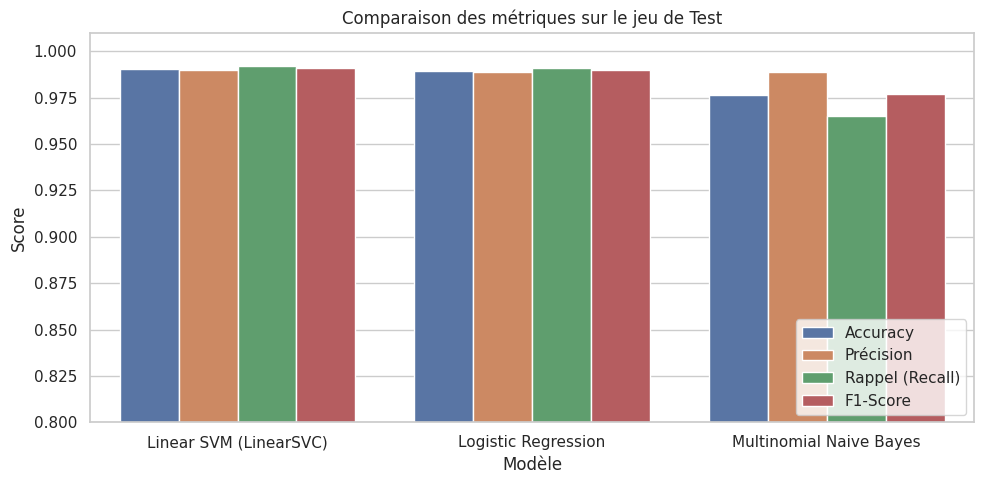

In [30]:
df_benchmark = pd.DataFrame(resultats_benchmark).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

# Affichage du tableau principal
colonnes_affichees = ["Modèle", "Accuracy", "Précision", "Rappel (Recall)", "F1-Score", "F1 CV (Train)", "Temps GridSearch (s)"]
display(df_benchmark[colonnes_affichees].style.format({
    "Accuracy": "{:.4f}",
    "Précision": "{:.4f}",
    "Rappel (Recall)": "{:.4f}",
    "F1-Score": "{:.4f}",
    "F1 CV (Train)": "{:.4f}"
}))

# Affichage des meilleurs hyperparamètres retenus pour chaque modèle
print("\n--- Meilleurs hyperparamètres trouvés ---")
for _, row in df_benchmark.iterrows():
    print(f"- {row['Modèle']} : {row['Meilleurs paramètres']}")

# Graphique comparatif des métriques sur le jeu de test
df_plot = df_benchmark.melt(
    id_vars="Modèle",
    value_vars=["Accuracy", "Précision", "Rappel (Recall)", "F1-Score"],
    var_name="Métrique",
    value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_plot, x="Modèle", y="Score", hue="Métrique")
plt.title("Comparaison des métriques sur le jeu de Test")
plt.ylim(0.80, 1.01)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Matrices de confusion et analyse des erreurs

Les scores globaux ne disent pas quel type d'erreur le modèle commet.

Filtrage d'e-mails :

- Faux Positifs (FP) : e-mail légitime classé comme phishing.
- Faux Négatifs (FN) : e-mail de phishing classé comme légitime.

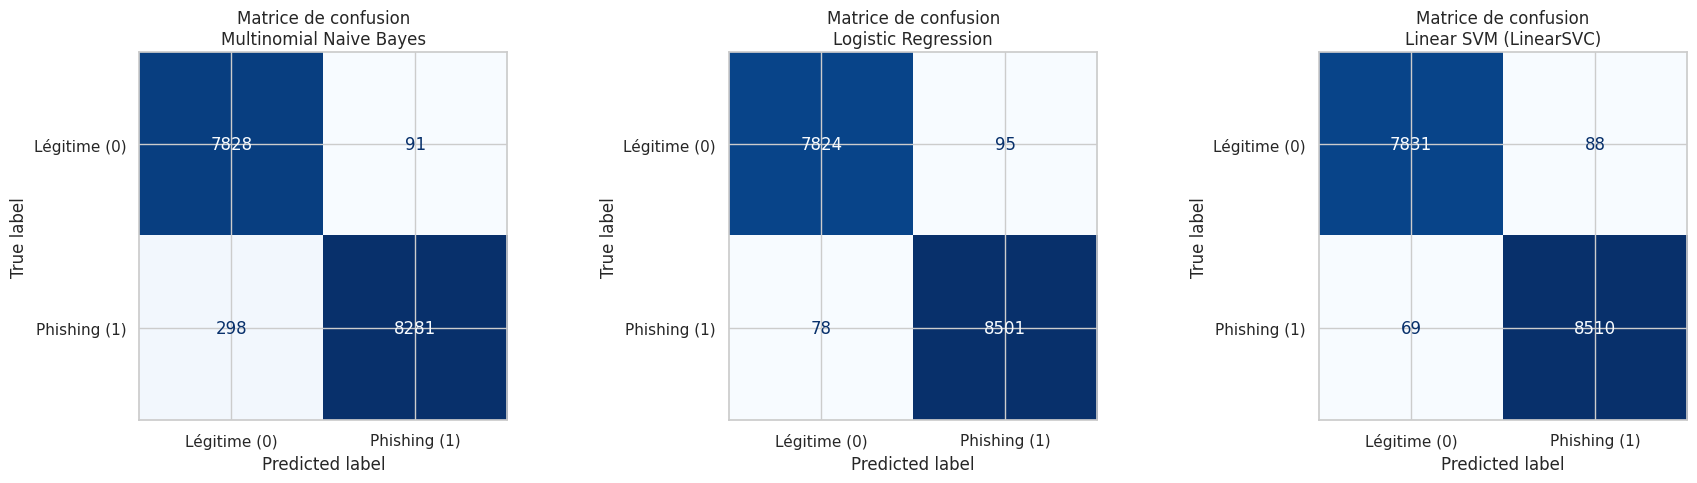

=== Rapport de classification détaillé du meilleur modèle : Linear SVM (LinearSVC) ===

              precision    recall  f1-score   support

Légitime (0)     0.9913    0.9889    0.9901      7919
Phishing (1)     0.9898    0.9920    0.9909      8579

    accuracy                         0.9905     16498
   macro avg     0.9905    0.9904    0.9905     16498
weighted avg     0.9905    0.9905    0.9905     16498



In [32]:
# Affichage côte à côte des 3 matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nom, y_pred) in zip(axes, predictions_test.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Légitime (0)", "Phishing (1)"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(f"Matrice de confusion\n{nom}")

plt.tight_layout()
plt.show()

# Rapport détaillé pour le meilleur modèle du benchmark
nom_gagnant = df_benchmark.loc[0, "Modèle"]
print(f"=== Rapport de classification détaillé du meilleur modèle : {nom_gagnant} ===\n")
print(classification_report(
    y_test,
    predictions_test[nom_gagnant],
    target_names=["Légitime (0)", "Phishing (1)"],
    digits=4
))

In [ ]:
# Récupération du meilleur modèle et de ses prédictions
modele_gagnant = meilleurs_modeles[nom_gagnant]
y_pred_gagnant = predictions_test[nom_gagnant]

# Récupération du score de confiance pour trier les erreurs les plus "graves"
# Plus le score est élevé, plus le modèle est sûr que c'est du phishing (1)
if hasattr(modele_gagnant, "predict_proba"):
    scores_confiance = modele_gagnant.predict_proba(X_test)[:, 1]
else:
    # Cas de LinearSVC qui n'a pas predict_proba mais decision_function
    scores_confiance = modele_gagnant.decision_function(X_test)

# Construction d'un DataFrame d'analyse sur le jeu de test
df_analyse = pd.DataFrame({
    "text": X_test.values,
    "vrai_label": y_test.values,
    "prediction": y_pred_gagnant,
    "score_phishing": scores_confiance
})
df_analyse["nb_mots"] = df_analyse["text"].str.split().str.len()
df_analyse["est_erreur"] = df_analyse["vrai_label"] != df_analyse["prediction"]

# Séparation des deux types d'erreurs
faux_positifs = df_analyse[(df_analyse["vrai_label"] == 0) & (df_analyse["prediction"] == 1)]
faux_negatifs = df_analyse[(df_analyse["vrai_label"] == 1) & (df_analyse["prediction"] == 0)]

print(f"=== Analyse des erreurs pour : {nom_gagnant} ===")
print(f"Total Faux Positifs (légitimes classés en phishing) : {len(faux_positifs)}")
print(f"Total Faux Négatifs (phishings laissés passer)      : {len(faux_negatifs)}")

# Comparaison de la longueur médiane entre bonnes prédictions et erreurs
print("\n--- Longueur médiane (en mots) : bonnes prédictions vs erreurs ---")
display(df_analyse.groupby("est_erreur")["nb_mots"].agg(["count", "median", "mean"]).round(1))


def afficher_exemples(df_sous_ensemble, titre, n=5, ordre_croissant=False):
    """Affiche un aperçu lisible de n e-mails mal classés."""
    print(f"\n{'='*70}\n{titre} (Top {n} erreurs les plus confiantes)\n{'='*70}")
    echantillon = df_sous_ensemble.sort_values(by="score_phishing", ascending=ordre_croissant).head(n)

    for i, (_, row) in enumerate(echantillon.iterrows(), 1):
        # On retire les sauts de ligne et on tronque à 300 caractères pour la lisibilité
        apercu = " ".join(row["text"].split())[:300]
        if len(apercu) == 0:
            apercu = "[TEXTE VIDE]"
        print(f"\n[{i}] Longueur : {row['nb_mots']} mots | Score phishing : {row['score_phishing']:.3f}")
        print(f"Extrait : {apercu}...")


# Faux Positifs : tri décroissant (le modèle était très sûr que c'était du phishing)
afficher_exemples(
    faux_positifs,
    "FAUX POSITIFS (Vrai = Légitime 0 | Prédit = Phishing 1)",
    n=5,
    ordre_croissant=False
)

# Faux Négatifs : tri croissant (le modèle était très sûr que c'était légitime)
afficher_exemples(
    faux_negatifs,
    "FAUX NÉGATIFS (Vrai = Phishing 1 | Prédit = Légitime 0)",
    n=5,
    ordre_croissant=True
)

=== Analyse des erreurs pour : Linear SVM (LinearSVC) ===
Total Faux Positifs (légitimes classés en phishing) : 89
Total Faux Négatifs (phishings laissés passer)      : 69

--- Longueur médiane (en mots) : bonnes prédictions vs erreurs ---


,count,median,mean
est_erreur,,,
False,16340,79.0,160.2
True,158,64.0,153.7



FAUX POSITIFS (Vrai = Légitime 0 | Prédit = Phishing 1) (Top 5 erreurs les plus confiantes)

[1] Longueur : 12 mots | Score phishing : 1.237
Extrait : marko žlogar ecssjjivnregvcceaschallengecc httpwww3delavnicacomuploadsigmundfredihtm wed 06 aug 2008 043813 0100 fredy animator...

[2] Longueur : 39 mots | Score phishing : 1.129
Extrait : registrationspsscom thank registering account spsscom please use verify email address link complete registration process clicking link activate account account activated full access spsscom need authenticate email future logins verify email address thu 07 aug 2008 093102 0400 spsscom verification...

[3] Longueur : 20 mots | Score phishing : 1.042
Extrait : catherine dempsey kovwteefquqyluvdgmailcom hi burn going evacuated ash falling sky catherine thu 07 aug 2008 051931 0100 gc fire aaahaaaahhh...

[4] Longueur : 515 mots | Score phishing : 0.836
Extrait : 6 943 disc non decimal counting systems fulfulde language west africa based fives separate wor

## 7. Modélisation Deep Learning et comparaison avec le Machine Learning

1. **Deux architectures adaptées au texte :**

    - **MLP sur Embeddings (Embedding + [tensorflow - GlobalAveragePooling1D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GlobalAveragePooling1D) + Dense) :** Version neuronale simple, qui apprend une représentation vectorielle de chaque mot avant de faire la moyenne sur  le message.

    - **CNN 1D (Embedding + [tensorflow - Conv1D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv1D) + GlobalMaxPooling1D) :** Applique des filtres de convolution sur des suites de mots consécutifs (un peu comme des n-grammes auto), efficace pour repérer des tournures de phrases de phishing tout en restant beaucoup plus rapide à entraîner qu'un LSTM.

2. **Un pipeline de bout en bout :** On intègre la couche TextVectorization directement à l'entrée du réseau Keras. Le modèle prend ainsi du texte brut en entrée et produit la prédiction en sortie, sur le même principe que Pipeline dans scikit-learn (et sans dataleakage, car le vocabulaire est appris uniquement sur le train).

3. **Grille de paramètres avec jeu de validation et Early Stopping :** Une validation croisée complète sur une grille Deep Learning est très coûteuse en temps de calcul => On découpe X_train_clean en Train (80%) / Validation (20%) pour sélectionner la meilleure combinaison d'hyperparamètres selon le F1-Score, avec un arrêt anticipé (EarlyStopping) dès que la perte de validation cesse de monter.

In [33]:
print("GPU :", tf.config.list_physical_devices("GPU"))

# Découpage du jeu d'entraînement nettoyé en Train (80%) et Validation (20%)
X_train_dl, X_val_dl, y_train_dl, y_val_dl = train_test_split(
    X_train_clean,
    y_train_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_train_clean
)

print(f"Train DL : {len(X_train_dl)} | Validation DL : {len(X_val_dl)} | Test : {len(X_test)}")

# Création de datasets TensorFlow optimisés par mini-bayches
BATCH_SIZE = 128

def creer_dataset(textes, labels=None, melanger=False):
    textes_liste = textes.tolist()
    if labels is not None:
        ds = tf.data.Dataset.from_tensor_slices((textes_liste, labels.to_numpy(dtype=np.float32)))
        if melanger:
            ds = ds.shuffle(buffer_size=10000, seed=42)
    else:
        ds = tf.data.Dataset.from_tensor_slices(textes_liste)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train DL : 50842 | Validation DL : 12711 | Test : 16498


In [34]:
train_ds = creer_dataset(X_train_dl, y_train_dl, melanger=True)
val_ds = creer_dataset(X_val_dl, y_val_dl, melanger=False)
test_ds = creer_dataset(X_test, melanger=False)

# Apprentissage uniquement sur X_train_dl (dataleakage)
MAX_TOKENS = 20000
SEQ_LENGTH = 250  # Longueur maxde mot par e-mails

vectoriseur_base = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQ_LENGTH
)
vectoriseur_base.adapt(tf.data.Dataset.from_tensor_slices(X_train_dl.tolist()).batch(512))
vocabulaire = vectoriseur_base.get_vocabulary()

print(f"Vocabulaire appris : {len(vocabulaire)} tokens.")

Vocabulaire appris : 20000 tokens.


### 7.1 Définition des pipelines Deep Learning et recherche par grille

On teste deux hyperparamètres clés par architecture (4 configurations par modèle afin de garder un temps d'exécution raisonnable sur mon ordinateur portable) :

- **embedding_dim :** taille du vecteur qui représente chaque mot (32 ou 64).
- **dropout :** taux de neurones désactivés aléatoirement à l'entraînement pour limiter le surapprentissage.
- **filters :** Pour le **CNN 1D**, on ajuste en plus le nombre de filtres de convolution.

In [35]:
# Builder de pipelines Keras de bout en bout (texte brut => prédiction).
def construire_pipeline_dl(architecture, vocab, embedding_dim=32, dropout_rate=0.3, filters=64, lr=1e-3):
    couche_vectorisation = layers.TextVectorization(
        max_tokens=len(vocab),
        output_mode="int",
        output_sequence_length=SEQ_LENGTH,
        vocabulary=vocab
    )

    if architecture == "DL - MLP (Embedding)":
        modele = keras.Sequential([
            keras.Input(shape=(), dtype=tf.string),
            couche_vectorisation,
            layers.Embedding(input_dim=len(vocab) + 1, output_dim=embedding_dim),
            layers.GlobalAveragePooling1D(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(1, activation="sigmoid")
        ])

    elif architecture == "DL - CNN 1D":
        modele = keras.Sequential([
            keras.Input(shape=(), dtype=tf.string),
            couche_vectorisation,
            layers.Embedding(input_dim=len(vocab) + 1, output_dim=embedding_dim),
            layers.Conv1D(filters=filters, kernel_size=5, activation="relu"),
            layers.GlobalMaxPooling1D(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(dropout_rate),
            layers.Dense(1, activation="sigmoid")
        ])

    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return modele

In [36]:
# Grilles d'hyperparamètres pour nos 2 architectures
grilles_dl = {
    "DL - MLP (Embedding)": {
        "embedding_dim": [32, 64],
        "dropout_rate": [0.3, 0.5],
        "filters": [None]  # le MLP n'a pas de filter => que le CNN
    },
    "DL - CNN 1D": {
        "embedding_dim": [32, 64],
        "dropout_rate": [0.3, 0.5],
        "filters": [64]
    }
}

In [37]:
EPOCHS_MAX = 8
resultats_dl = []
meilleurs_modeles_dl = {}
historiques_dl = {}
predictions_test_dl = {}

for nom_modele, grille in grilles_dl.items():
    print(f"\n==================================\nGrid Search Deep Learning : {nom_modele}\n==================================")
    debut_grille = time.time()

    meilleur_f1_val = -1.0
    meilleur_modele = None
    meilleurs_params = None
    meilleur_historique = None

    # Génération de toutes les combinaisons de la grille
    cles = list(grille.keys())
    combinaisons = list(itertools.product(*grille.values()))

    for i, valeurs in enumerate(combinaisons, 1):
        params = dict(zip(cles, valeurs))
        params_propres = {k: v for k, v in params.items() if v is not None}
        print(f"\n[{i}/{len(combinaisons)}] Test des paramètres : {params_propres}")

        modele = construire_pipeline_dl(
            architecture=nom_modele,
            vocab=vocabulaire,
            embedding_dim=params["embedding_dim"],
            dropout_rate=params["dropout_rate"],
            filters=params["filters"] if params["filters"] else 64
        )

        # Early Stopping si val_loss ne baisse pas pendant 2 EPOCH
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )

        historique = modele.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS_MAX,
            callbacks=[early_stop],
            verbose=1
        )

        # Eval de la configuration i sur le jeu de validation (F1-Score)
        probas_val = modele.predict(val_ds, verbose=0).ravel()
        preds_val = (probas_val >= 0.5).astype(int)
        f1_val = f1_score(y_val_dl, preds_val)
        print(f" -> F1-Score Validation : {f1_val:.4f}")

        # On remplace par le meilleur modèle à chaque fois que f1_val devient meilleur
        if f1_val > meilleur_f1_val:
            meilleur_f1_val = f1_val
            meilleur_modele = modele
            meilleurs_params = params_propres
            meilleur_historique = historique.history

    duree_grille = time.time() - debut_grille

    # Eval finale du meilleur modèle sur le jeu de Test
    probas_test = meilleur_modele.predict(test_ds, verbose=0).ravel()
    y_pred_test = (probas_test >= 0.5).astype(int)

    meilleurs_modeles_dl[nom_modele] = meilleur_modele
    historiques_dl[nom_modele] = meilleur_historique
    predictions_test_dl[nom_modele] = y_pred_test

    resultats_dl.append({
        "Modèle": nom_modele,
        "Famille": "Deep Learning",
        "Accuracy": accuracy_score(y_test, y_pred_test),
        "Précision": precision_score(y_test, y_pred_test),
        "Rappel (Recall)": recall_score(y_test, y_pred_test),
        "F1-Score": f1_score(y_test, y_pred_test),
        "F1 Val / CV": meilleur_f1_val,
        "Temps GridSearch (s)": round(duree_grille, 1),
        "Meilleurs paramètres": meilleurs_params
    })

    print(f"\n===> Meilleure config {nom_modele} : {meilleurs_params} | F1 Test : {f1_score(y_test, y_pred_test):.4f}")


Grid Search Deep Learning : DL - MLP (Embedding)

[1/4] Test des paramètres : {'embedding_dim': 32, 'dropout_rate': 0.3}
Epoch 1/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8629 - loss: 0.3266 - val_accuracy: 0.9704 - val_loss: 0.1086
Epoch 2/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9705 - loss: 0.0906 - val_accuracy: 0.9766 - val_loss: 0.0693
Epoch 3/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9821 - loss: 0.0576 - val_accuracy: 0.9774 - val_loss: 0.0628
Epoch 4/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9849 - loss: 0.0458 - val_accuracy: 0.9762 - val_loss: 0.0664
Epoch 5/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9880 - loss: 0.0373 - val_accuracy: 0.9867 - val_loss: 0.0470
Epoch 6/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9890 - loss: 0.0320 - val_accuracy: 0.9872 - val_loss: 0.0479
Epoch 7/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9923 - loss: 0.0235 - val_accuracy: 0.9806 - v

## 7.2 Courbes d'apprentissage et benchmark global (Machine Learning vs Deep Learning)

- Les courbes de perte (loss) sur le Train et la validation permettent de vérifier que nos réseaux convergent correctement sans surapprentissage marqué (la courbe de validation ne doit pas remonter fortement alors que la perte d'entraînement baisse).
- On fusionne les résultats dans un tableau et un graphique comparatif pour évaluer le rapport performance / temps de calcul entre les modèles ML classiques et les modèles Deep Learning.

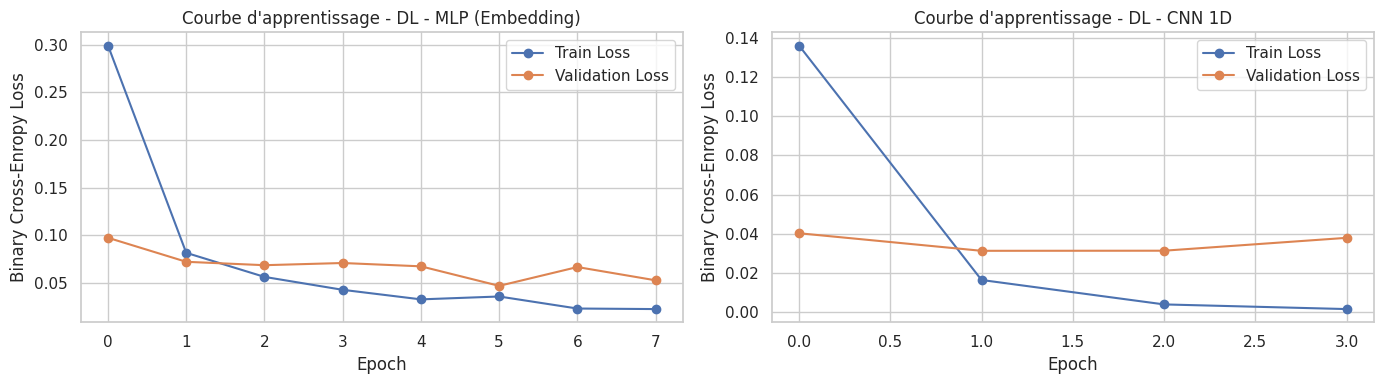

=== Benchmark global : Machine Learning vs Deep Learning ===


,Modèle,Famille,Accuracy,Précision,Rappel (Recall),F1-Score,F1 Val / CV,Temps GridSearch (s)
0,Linear SVM (LinearSVC),Machine Learning,0.9905,0.9898,0.9920,0.9909,0.9900,371.400000
1,Logistic Regression,Machine Learning,0.9895,0.9889,0.9909,0.9899,0.9890,345.700000
2,DL - CNN 1D,Deep Learning,0.9871,0.9881,0.9872,0.9876,0.9901,99.700000
3,DL - MLP (Embedding),Deep Learning,0.9844,0.9876,0.9824,0.9850,0.9876,120.200000
4,Multinomial Naive Bayes,Machine Learning,0.9764,0.9891,0.9653,0.9771,0.9765,509.000000


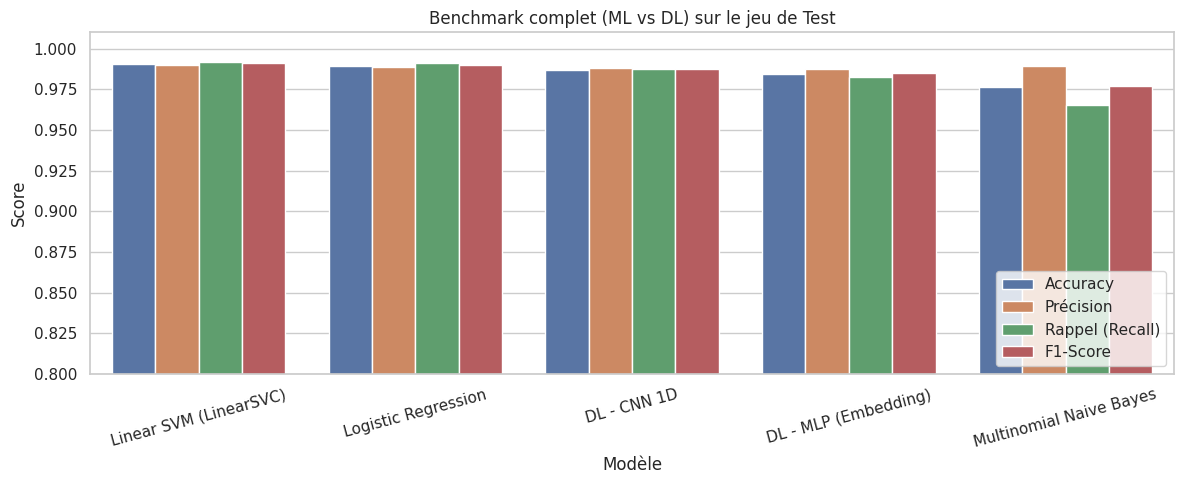

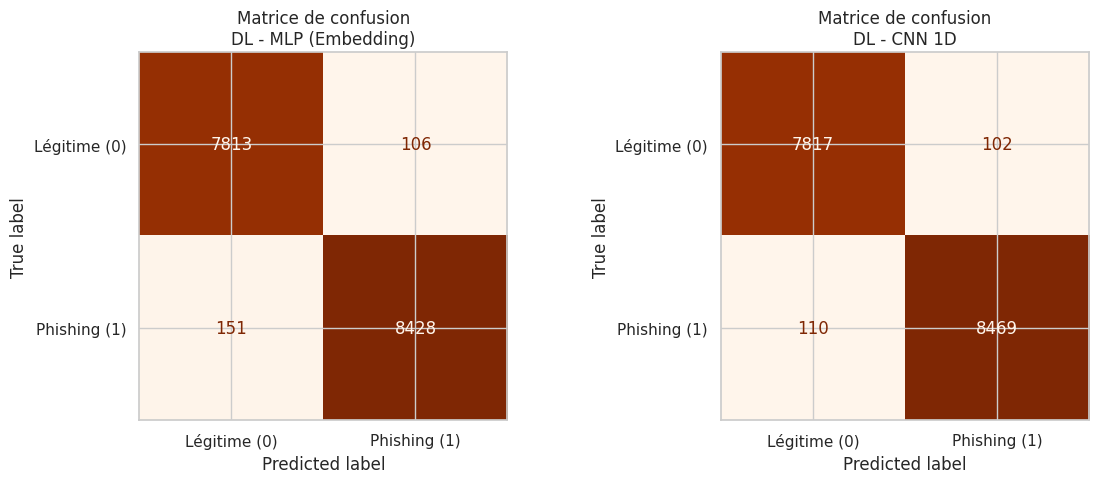

In [38]:
# Courbes de perte (Train vs Validation) des meilleurs modèles DL
fig, axes = plt.subplots(1, len(historiques_dl), figsize=(14, 4))

for ax, (nom, hist) in zip(axes, historiques_dl.items()):
    ax.plot(hist["loss"], label="Train Loss", marker="o")
    ax.plot(hist["val_loss"], label="Validation Loss", marker="o")
    ax.set_title(f"Courbe d'apprentissage - {nom}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Enropy Loss")
    ax.legend()

plt.tight_layout()
plt.show()

# Fusion avec le benchmark ML fait au début
df_ml_prepare = df_benchmark.copy()
df_ml_prepare["Famille"] = "Machine Learning"
df_ml_prepare = df_ml_prepare.rename(columns={"F1 CV (Train)": "F1 Val / CV"})

df_dl_prepare = pd.DataFrame(resultats_dl)

df_benchmark_global = pd.concat(
    [df_ml_prepare, df_dl_prepare],
    ignore_index=True
).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

colonnes_globales = [
    "Modèle", "Famille", "Accuracy", "Précision",
    "Rappel (Recall)", "F1-Score", "F1 Val / CV", "Temps GridSearch (s)"
]

print("=== Benchmark global : Machine Learning vs Deep Learning ===")
display(df_benchmark_global[colonnes_globales].style.format({
    "Accuracy": "{:.4f}",
    "Précision": "{:.4f}",
    "Rappel (Recall)": "{:.4f}",
    "F1-Score": "{:.4f}",
    "F1 Val / CV": "{:.4f}"
}))

# affichage F1-Score et Recall pour tous les modèles
df_plot_global = df_benchmark_global.melt(
    id_vars=["Modèle", "Famille"],
    value_vars=["Accuracy", "Précision", "Rappel (Recall)", "F1-Score"],
    var_name="Métrique",
    value_name="Score"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=df_plot_global, x="Modèle", y="Score", hue="Métrique")
plt.title("Benchmark complet (ML vs DL) sur le jeu de Test")
plt.ylim(0.80, 1.01)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Matrices de confusion des 2 modèles Deep Learning
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nom, y_pred) in zip(axes, predictions_test_dl.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Légitime (0)", "Phishing (1)"],
        cmap="Oranges",
        colorbar=False,
        ax=ax
    )
    ax.set_title(f"Matrice de confusion\n{nom}")

plt.tight_layout()
plt.show()

# Conclusions

Pour ce projet, LinearSVC (ou Logistic Regression si l'on veut piloter le seuil de probabilité) représente donc le meilleur compromis entre performance, stabilité et simplicité de déploiement.

Pour ce genre de problématique de NLP, un bon pipeline de Machine Learning classique reste souvent plus efficace que des réseaux de neurones entraînés from scratch.